# E96: Can we find which part of the model a fine-tune runs through, without being told where to look?

**The answer.** For narrow copying, yes. Switching off each of the 24 attention heads in turn names head (2,4), and earlier work had already pointed there. For the broad lowercase task, no. No head or pair removes the gain, and about half of the best share is the original model moving. So this is a working method for narrow copying-type behaviour, a known failure on broad strengthening, and no cheap way to choose parts.

*Status: provisional, no independent check. A new circuit built from old parts still reads as reuse, on every claim below that names a part.*


## What we were trying to test

`GOALS.md` asks whether post-training teaches new capabilities or strengthens existing ones. The project's definition gives a label only through a located mechanism. That is a part of the model whose removal takes the behaviour and spares a control task. So we need a locator that is not told the answer.

**The states.** A state is a saved fine-tuned copy of the 67M model; W₀ is the original. Three seeds each learn copying at a marker, "A B ... A M" giving B, and a lookup on the same windows, "A M" giving a fixed word. Two seeds each learn to continue lowercase text, which W₀ already does a little, and a word cipher.

**The cut.** Switching a head off replaces its output with W₀'s average on natural text, at every position, in both W₀ and the state. The gain $G$ is the state's log-odds of the target minus W₀'s. The net share is $1 - G_{off}/G$, where 0 means the head carries none of the gain and 1 means all of it.

**The sweep and the nominators.** The sweep cuts each head alone, then the best pair found greedily. Three cheap nominators are scored against it, because 24 heads is affordable and larger sets of parts are not. They are one gradient step per head, the same score on MLP units taking the top 320, and a probe reading the target from each head.

**The controls.** The lookup asks whether a head named for copying is merely important everywhere, and the cipher asks the same of lowercase. The zero update reads a gain of exactly 0.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/locate_mechanism/figures")


## What we expected, and why

The sweep should name (2,4) on copying at about half of the gain, because an earlier experiment found that head by its prefix score. That makes this control weak, since choosing heads as the unit is already partly being told where to look.

We leaned towards the gradient step placing (2,4) in its top 3, as it estimates the same quantity. We leaned against the probe doing so, as a probe should favour heads downstream of the mechanism. We leaned towards MLP units being small and not specific, as an earlier unit removal found little. On lowercase we leaned towards no single head, because the behaviour is broad.


## What we observed

### Does a sweep of heads find the copying head by itself?


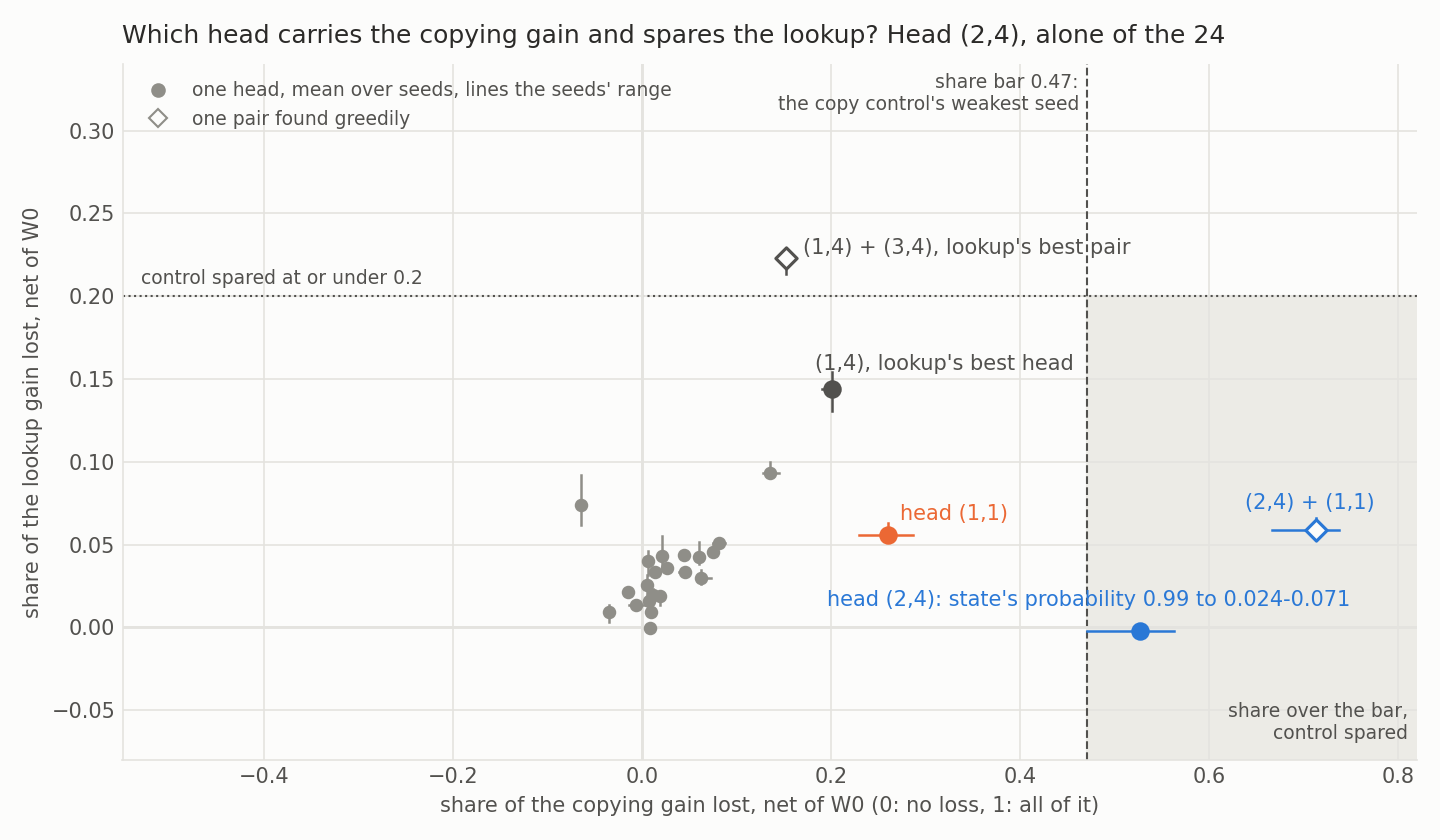

In [2]:
display(Image(FIG / "copy_lookup.png", width=900))


**Reading it.** Yes, and the control passes by its filed rule. Head (2,4) tops the sweep on all three seeds at a share of 0.47 to 0.56. Lookup's best head reads 0.13 to 0.15, and (2,4) costs the lookup nothing. With (2,4) off, the state's probability of the target falls from 0.99 to between 0.024 and 0.071. Earlier work had pointed at this head, so the pass shows little alone. A new circuit built from old parts would still read as reuse.


### Does one gradient step rank the heads as the sweep does?


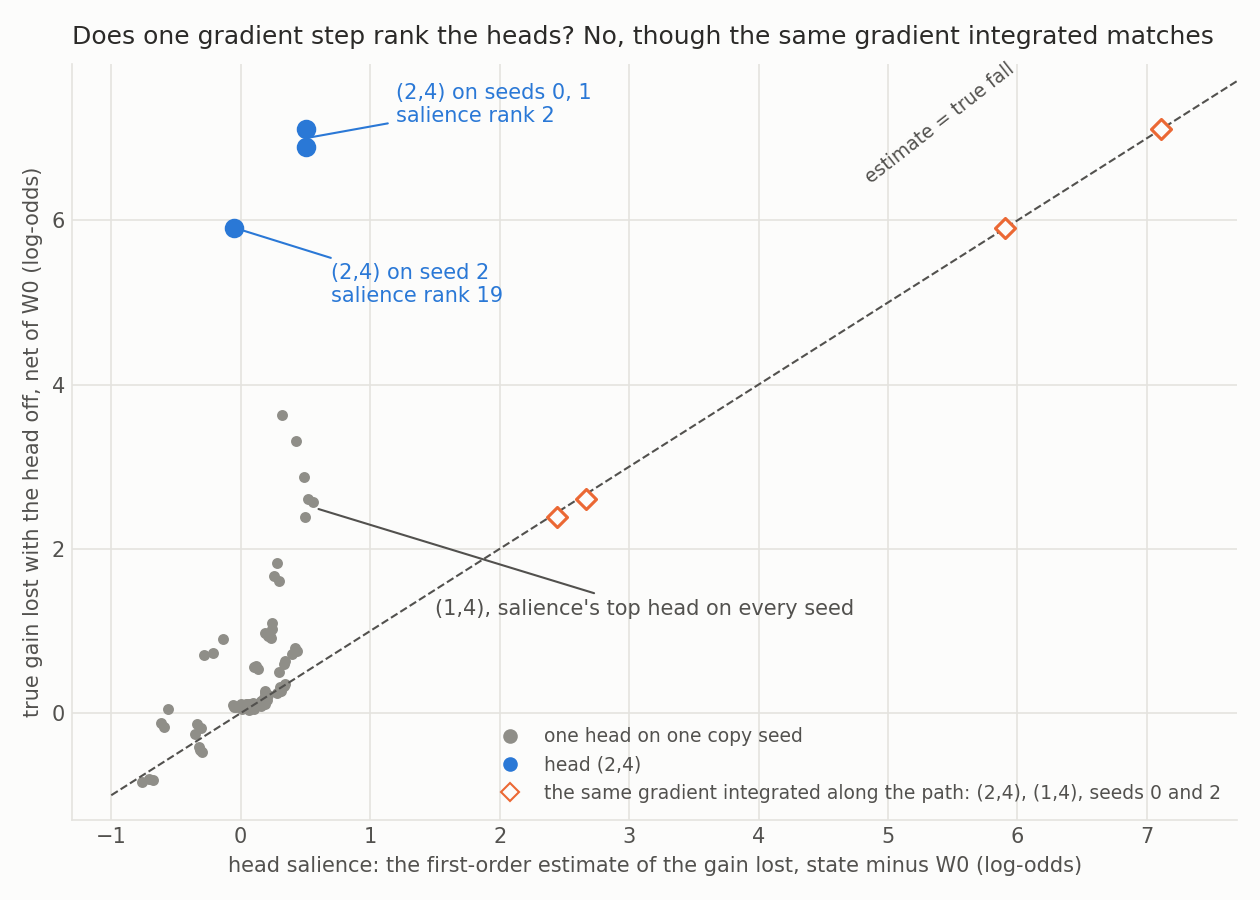

In [3]:
display(Image(FIG / "salience.png", width=800))


**Reading it.** No, this nominator failed. It ranks (2,4) second, second and nineteenth, and its top head on every seed is (1,4). The dashed line is where a right estimate would sit. The orange diamonds integrate the same gradient along the path from the head's output to its mean, and they land on that line. So the code is right and the first-order step misleads. We name no further cause.


### Does a probe show which head is used?


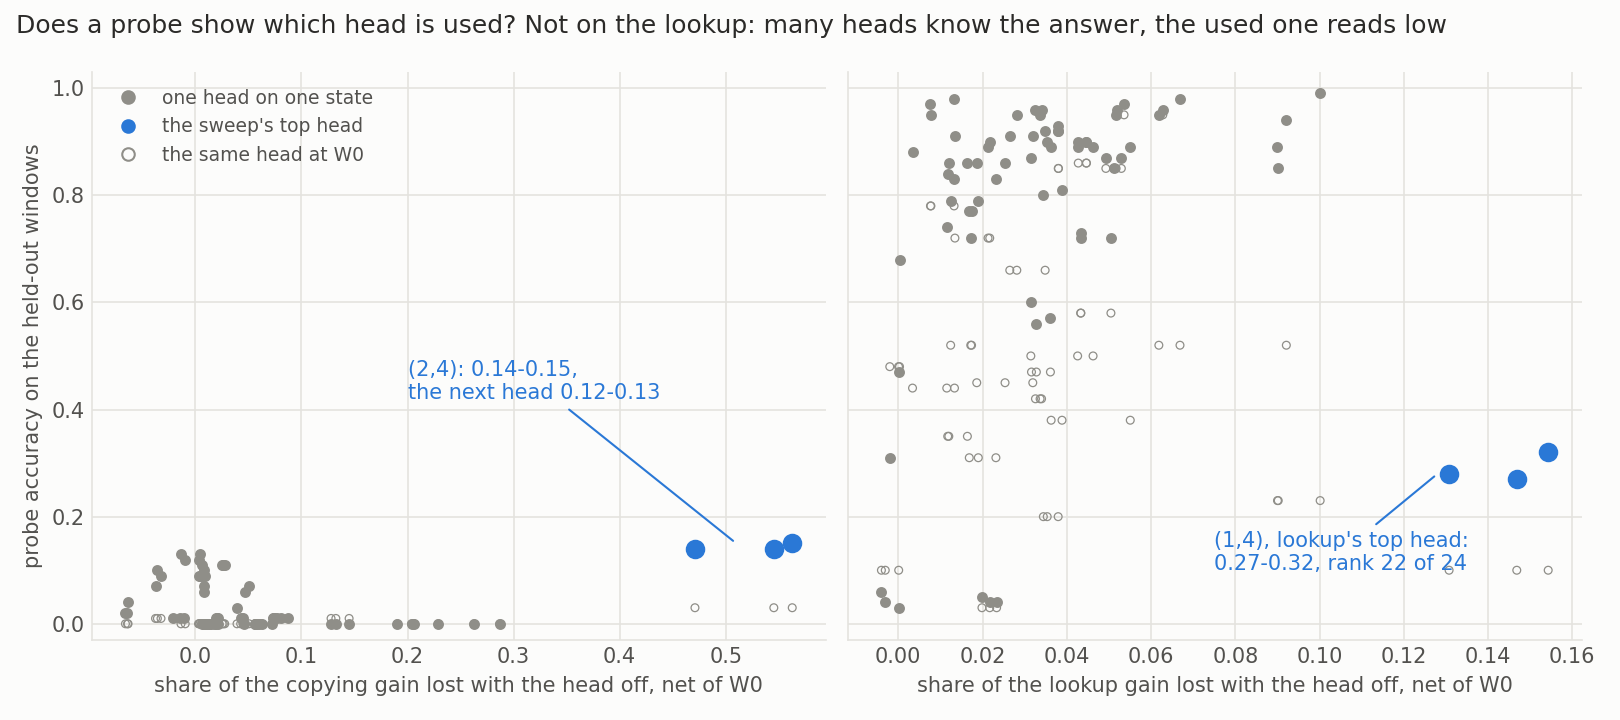

In [4]:
display(Image(FIG / "probe.png", width=950))


**Reading it.** Not on the lookup, and our filed lean on copying missed. We leaned that (2,4) would not make the top 3, yet it ranks first on all three seeds. That first place is only 0.14 to 0.15 against 0.12 to 0.13 on about 100 windows, not a distinguishable margin. On the lookup, three to seven heads read 0.95 or more, and the head that matters most ranks 22nd. A probe reads where a thing is known, not where it is used.


### Do the most salient MLP units carry the gain alone?


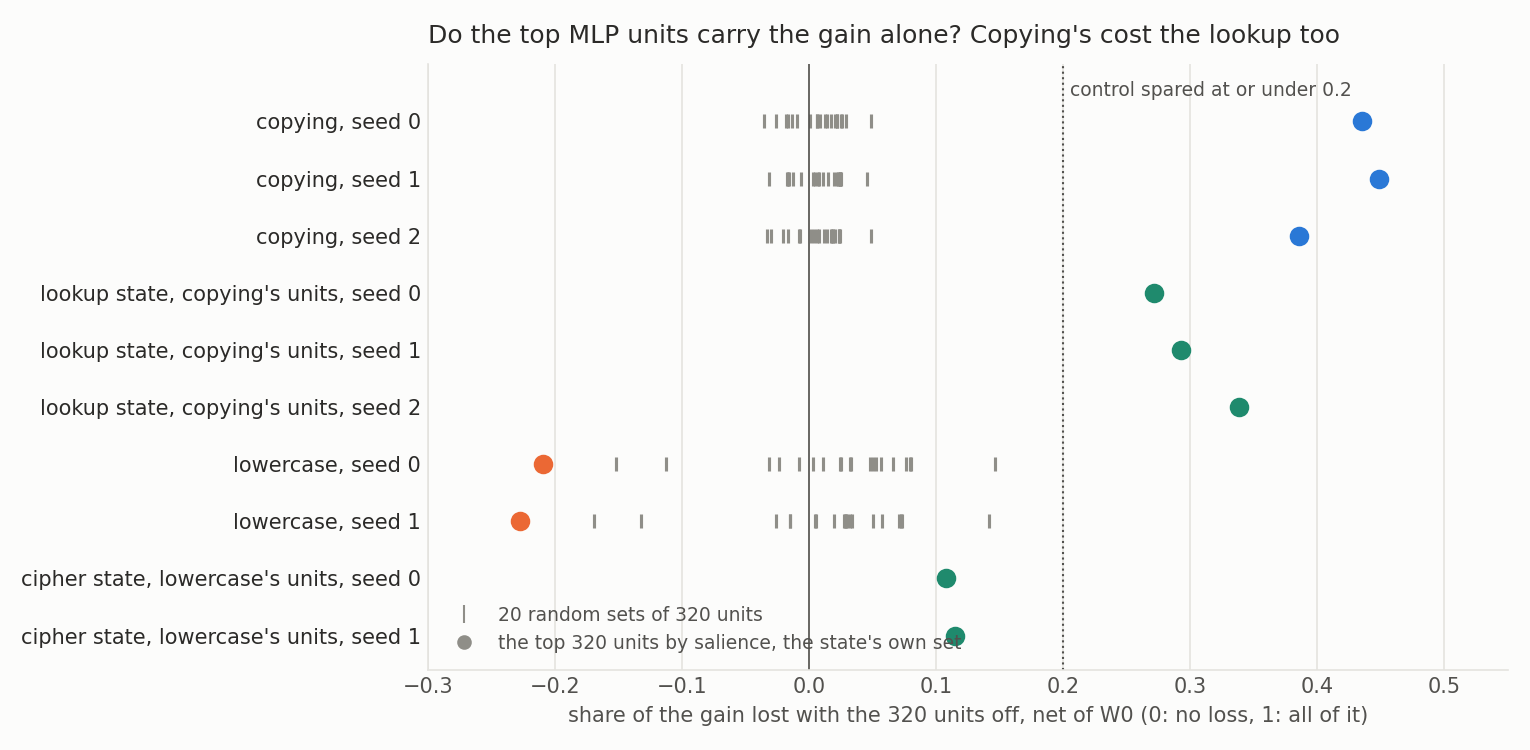

In [5]:
display(Image(FIG / "mlp_units.png", width=900))


**Reading it.** On copying they carry a lot of it and are not specific, so this filed lean missed too. The state's own 320 units take 0.39 to 0.45 of the gain, while no random set passes 0.05. Those same units cost the lookup state 0.27 to 0.34, over the 0.2 bar for a spared control. On lowercase the net share is negative, which a later figure explains.


### Does any head or pair carry the lowercase gain and spare the cipher?


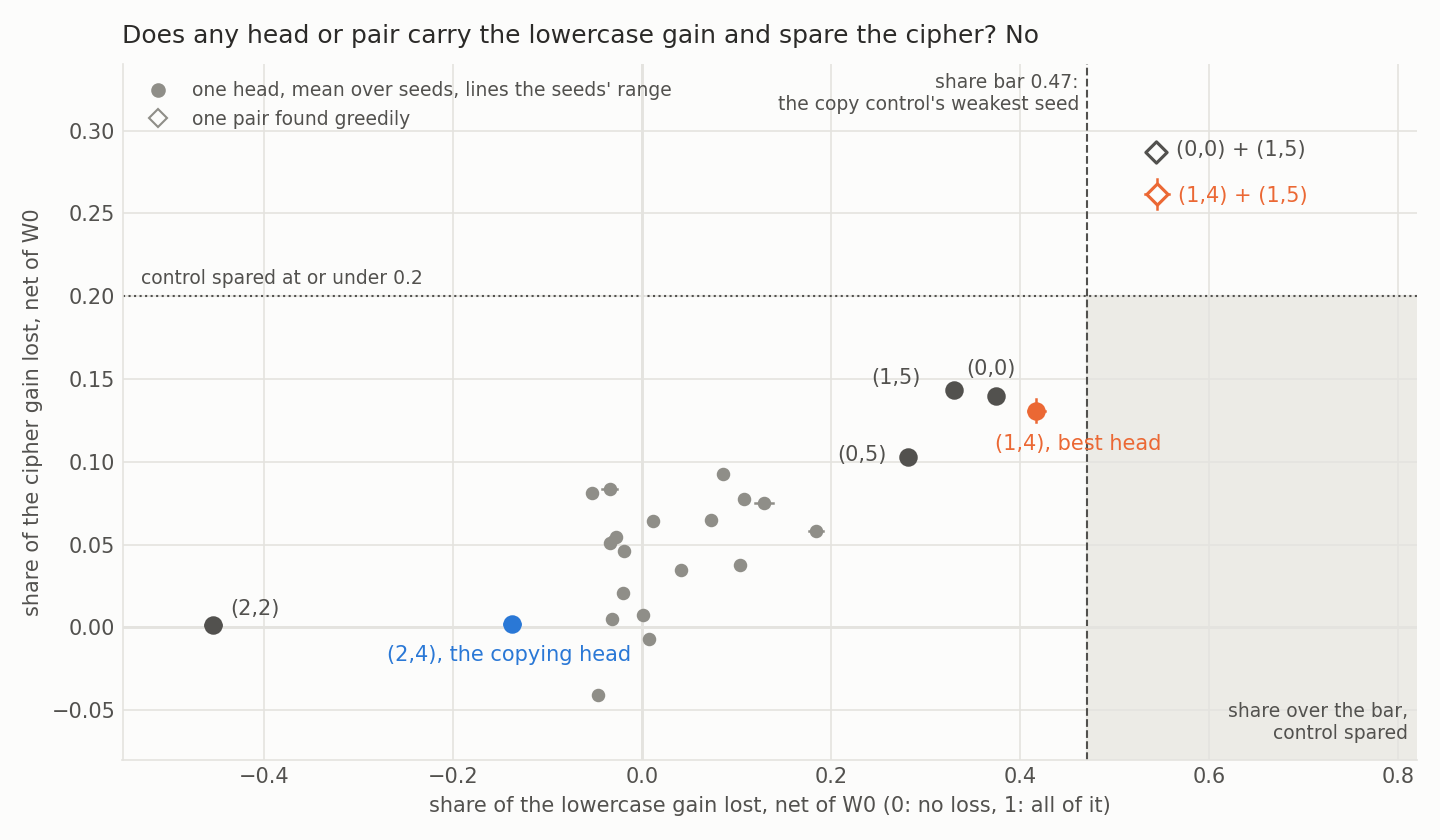

In [6]:
display(Image(FIG / "lowercase_cipher.png", width=900))


**Reading it.** No. The filed outcome is "not found at head or pair grain", and that scope is all it claims. The best head, (1,4), reads 0.41 to 0.43 on lowercase, under the 0.47 bar taken from the control's weakest seed. It costs the cipher 0.12 to 0.14. The best pairs read 0.53 to 0.56, and they fail because they cost the cipher 0.25 to 0.29. This is not "no mechanism", and a new circuit built from old parts would still read as reuse.


### Post hoc, unfiled: what is the net share made of?


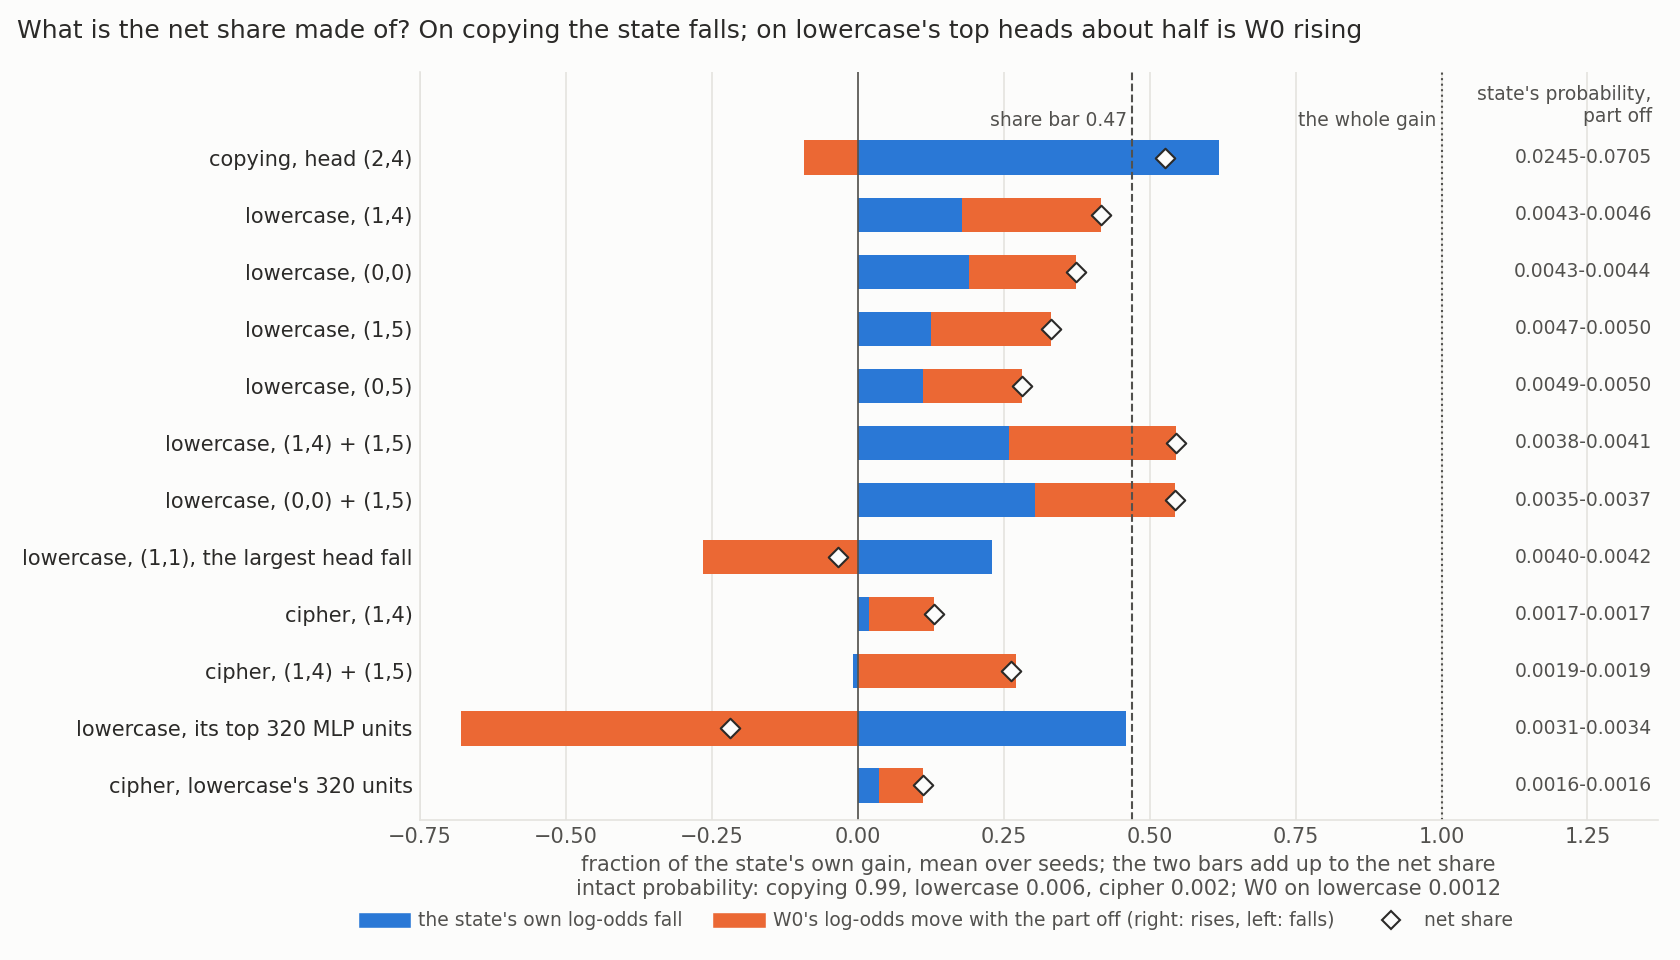

In [7]:
display(Image(FIG / "own_terms.png", width=950))


**Reading it.** This reading was not filed, and it makes the filed outcome firmer. Blue is how far the state's own log-odds fall, orange is how far W₀'s move, and together they make the net share. On copying, (2,4) takes the state down by 0.56 to 0.65 of its gain and W₀ falls too, so the net share is conservative. On lowercase, (1,4) moves W₀ from -6.76 to -6.37 and the state from -5.08 to -5.38. That state fall is only 0.29 of a 1.67 gain.

The state's probability stays near 0.004 against W₀'s 0.0012, never near removed. The four top-share heads all raise W₀'s log-odds of the rare target on both tasks. So on this task the sweep largely ranked W₀'s sensitivity to switching a head off, not a mechanism of the gain.


### Can a part take the gain and leave the original model's capability?


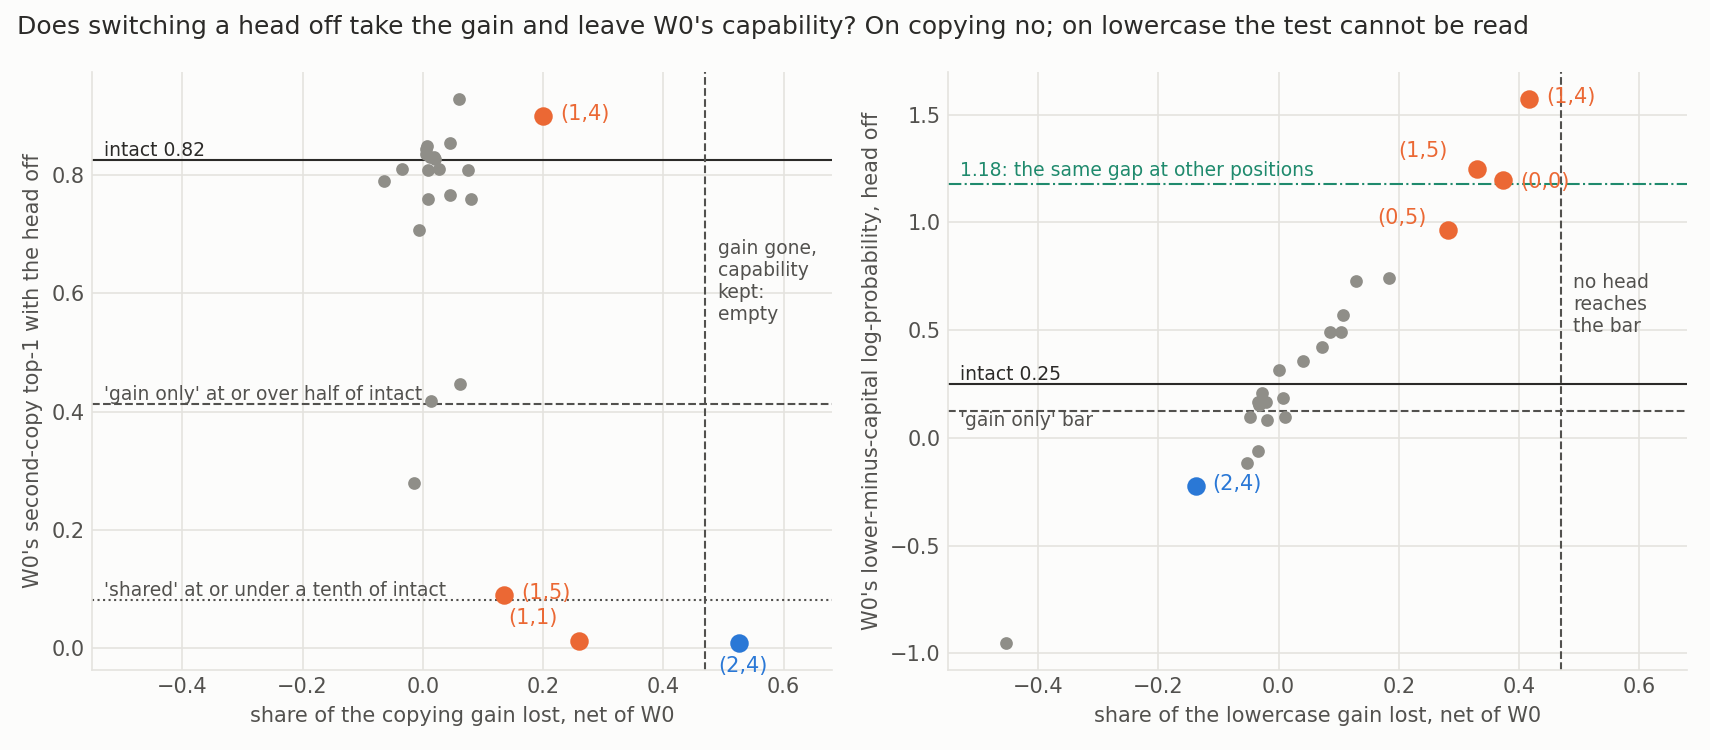

In [8]:
display(Image(FIG / "capability.png", width=1000))


**Reading it.** This is the user's test. If a part can be switched off so that the gain goes and W₀'s capability stays, the two have separate mechanisms. On copying the located part reads shared, because (2,4) off takes W₀'s second-copy accuracy from 0.82 to 0.0095. As a post hoc hint only, (1,5) takes that accuracy to 0.09 and costs 0.13 to 0.15 of the gain, read on two different behaviours.

On lowercase the question has no antecedent, because no part removes the gain. Seventeen heads read "gain only", and that is no evidence for separate mechanisms. The capability number is W₀'s lower-minus-capital gap, only 0.25 on these rows, and the bar is half of it. Twelve heads raise the gap, including the four top-share heads.

We read lowercase as unreadable at this grain. Beside it, marked behavioural, go W₀'s probability of the target, about 0.0012, and the fine-tune's gain, about 1.6. The definition's own verdict on this task stays "does not apply".


## What we learned

Mean-ablating heads is a working locator for narrow copying-type behaviour at head grain. It is a known failure on a broad strengthening task, where much of its reading is how W₀ reacts to losing a head. None of the three cheap nominators earned a place, so nothing here scales past a sweep. For `GOALS.md`, the copying pair keeps a located reading that reads shared, and lowercase gains no verdict.

## How compelling is the evidence

The control is two fine-tunes on one map family with three seeds, and it repeats what earlier work found. Lowercase rests on two seeds and one control task. The standard error of its top share is about 0.05. Head means come from 41-token spans, while lowercase's windows run 127 tokens. The sweep cannot see an effect needing more than two heads. The own-terms reading came after the data.


## Surprises

**Filed leans missed.** The probe ranked (2,4) first against a lean of "not top 3", by an indistinguishable margin. MLP units were large against a lean of small, and they were not spared. The gradient step, leaned to the top 3, ranked it 19th on one seed.

**One unexplained number.** W₀'s lower-minus-capital gap reads 0.25 here against an expected 1.18 from other positions of the same task. We do not know why, so the capability reading on lowercase is not relied on.

**One post hoc number.** Lowercase's own 320 units take the state down by 0.45 to 0.47 of its gain, more than any head or pair. They take the cipher down by 0.03 to 0.04. W₀ falls further still, which is why the net share is negative. Random sets were not read this way, and the gain is not removed.

Two table entries missed with no rule reading them: the lookup's probability with its top head off, and the lookup's greedy pair. The report has them.

## What next

1. Stop this line, as the review by Fable advised. Any head-level variant inherits the same reading on lowercase.
2. For the next task, report the state's own fall on the task and the control, beside the net share. A part taking 0.8 of the lowercase gain this way, with the cipher under 0.2, would change the reading.
3. If the definition's owner wants lowercase read at any grain, the one amendment goes on that rule with a greedy head set, expected "not found".


## Scorecard

| Id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| Stage 0 | Stored gains re-read, zero update zero | Difference 0; on E53's path within 0.02 | 0.0; at most 4e-16 | as filed |
| Control | (2,4) tops copy, located, lookup clear | Probability at most 0.1; lookup share at most 0.2 | 0.024-0.071; 0.00 | passes |
| Capability | (2,4) reads shared | Top-1 at most 0.082 | 0.0095 | as filed |
| Salience | Lean top 3 | Rank at most 3 on all seeds | 2, 2, 19 | failed |
| Probe | Lean not top 3 | Rank over 3 | 1, 1, 1 | lean missed |
| MLP units | Lean small, not specific | Against 20 random sets | 0.39-0.45; random up to 0.05; lookup 0.27-0.34 | lean missed |
| Stage 2 | Share at least 0.47, cipher at most 0.2 | Both seeds | (1,4) 0.41-0.43; pairs fail on cipher | not found at head or pair grain |
| Lean | No single head | No head over the bar | Maximum 0.43 | held |
| Gradient | Lean first-order step misleads | 10% tolerance | All four cases | held |


## Not run

A greedy set of heads. Ablation restricted to positions. Fewer MLP units. The narrow lowercase pair. The ladder. A planted head. Random unit sets in the state's own terms. W₀'s entropy with each head off. The report says what each would be for.

## Departures from the literature

- Jain et al. Alg. 3 scores MLP units by gradient times weight to prune and watch a capability revive. Here the importance sign is used, on the gain, also at head outputs, because the aim is location.
- From no paper: the 0.47 bar came from the control's weakest seed. Head means came from 41-token spans, while lowercase's windows run 127.

## Provenance

Results in `experiments/locate_mechanism/results/`; plan `reports/plans/2026-11-05_plan_e96-locate-mechanism.md`; advice `reports/reviews/2026-11-05_review_e96-next-fable-advice.md`; report `reports/analyses/2026-11-05_analysis_e96-locate-mechanism.md`. Jobs 52551 and 52567, debug L40, $0.
